# SQL-аналитика: Resume Analyzer

Этот ноутбук закрывает **требование 10** (SQLite, ER-диаграмма, ≥ 8 SQL-запросов с JOIN, GROUP BY/HAVING, CTE/подзапросами и оконными функциями, результаты в Pandas) и пункты 7–8 списка доработок.

**Данные:** `data/resume_data.csv` — [Resume Dataset (Kaggle)](https://www.kaggle.com/datasets/saugataroyarghya/resume-dataset).

**Важно о структуре данных:** 9 544 строки — это не 9 544 резюме, а **344 уникальных резюме × 28 вакансий** (пары «резюме–вакансия») с оценкой соответствия `matched_score`. Поэтому база нормализована: резюме, вакансии и навыки хранятся по одному разу, а оценки — в отдельной таблице `matches`.

Код базы: `database.py` (схема — `db/schema.sql`), запросы — `sql_queries.py`.

In [1]:
import time
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from database import create_database, run_query, load_resume_csv, DEFAULT_DB
from sql_queries import QUERIES, run_named

pd.set_option("display.max_colwidth", 60)

BLUE = "#2a78d6"   # один цвет для всех одно-серийных графиков
def style_ax(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, fontsize=13, loc="left")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Создание базы данных SQLite из CSV

In [2]:
start = time.perf_counter()
counts = create_database()          # data/resume_data.csv -> resume_analyzer.db
print(f"База построена за {time.perf_counter() - start:.2f} с: {DEFAULT_DB.name}\n")
pd.DataFrame(counts.items(), columns=["таблица", "строк"])

База построена за 1.11 с: resume_analyzer.db



,таблица,строк
0,resumes,344
1,jobs,33
2,skills,3089
3,resume_skills,7642
4,job_skills,177
5,education,565
6,experience,963
7,matches,9544


## 2. ER-диаграмма

Схема в третьей нормальной форме: навыки хранятся один раз в `skills`, связи «многие-ко-многим» вынесены в `resume_skills` и `job_skills`, повторяющиеся списки (образование, опыт) — в отдельные таблицы. `matches` хранит истинные метки из датасета, `analysis_results` / `analysis_skills` — результаты анализа из веб-приложения.

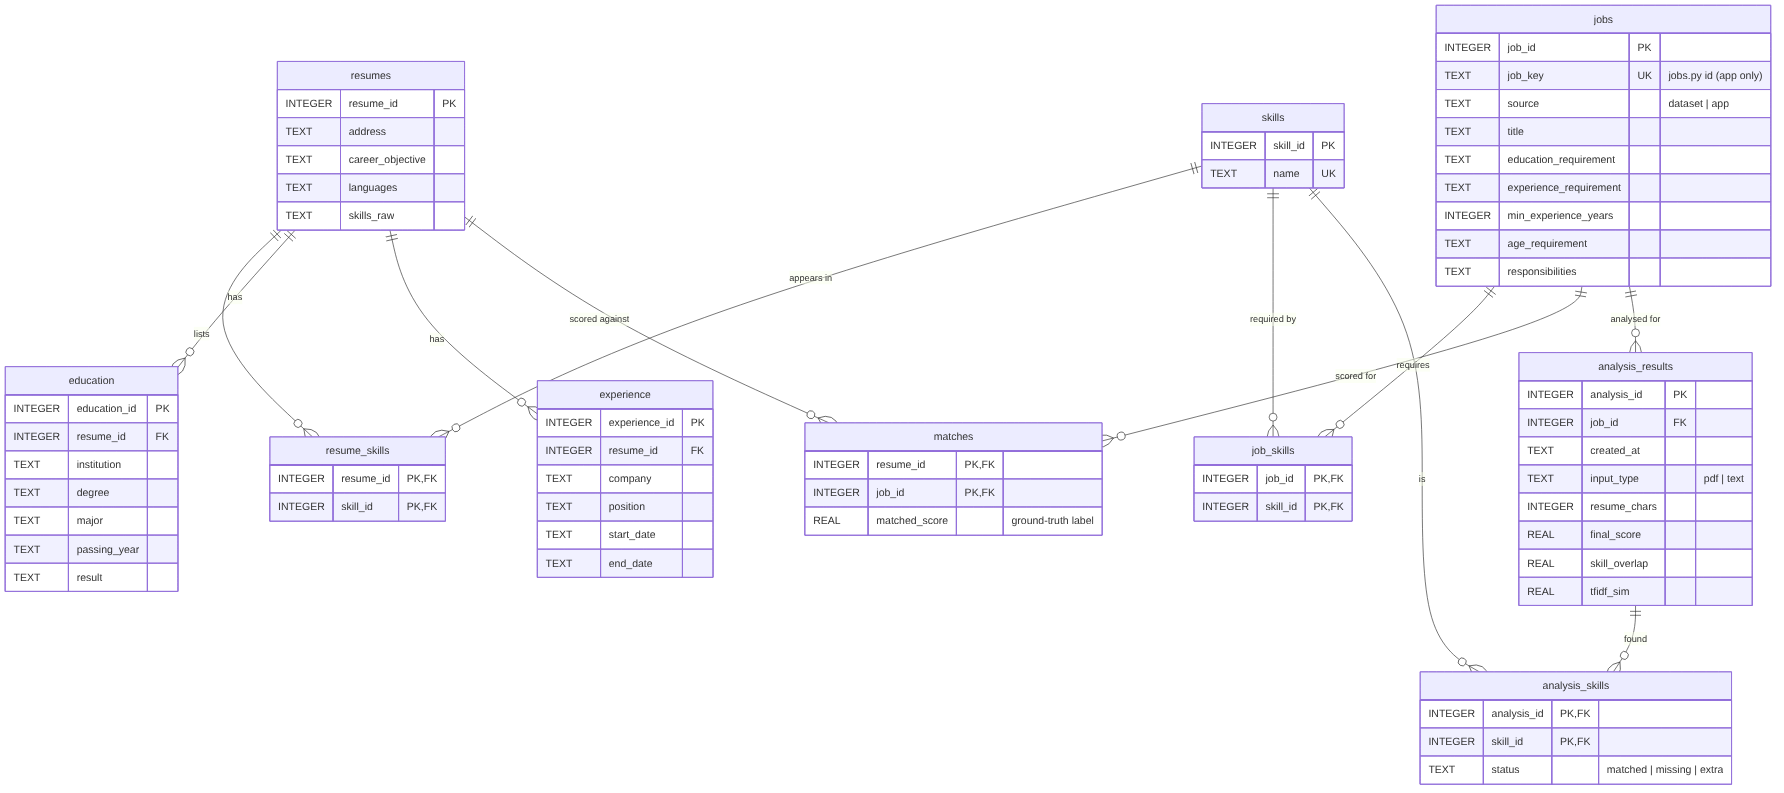

In [3]:
display(Image(filename="docs/er_diagram.png"))

## 3. SQL-запросы

| № | Запрос | Техники SQL |
|---|---|---|
| 1 | Most common skills in resumes | JOIN, GROUP BY, ORDER BY/LIMIT |
| 2 | Skill gap: demand from jobs vs supply in resumes | CTE, LEFT JOIN, GROUP BY/HAVING, COALESCE |
| 3 | Average match score per job, ranked | JOIN, GROUP BY/HAVING, window RANK() |
| 4 | Top-3 recommended jobs for each candidate | CTE, window ROW_NUMBER() PARTITION BY, JOIN |
| 5 | Skill-overlap score computed in SQL vs the ground-truth label | multiple CTEs, LEFT JOIN, GROUP BY, CASE |
| 6 | Candidates whose average score beats the overall average | subquery in HAVING, correlated subquery, GROUP BY |
| 7 | Match scores by required experience, with cumulative share | CASE bucketing, GROUP BY, window SUM() OVER (running total) |
| 8 | Where a candidate stands among all applicants for each job | window NTILE(), PERCENT_RANK(), AVG() OVER (PARTITION BY), subquery |
| 9 | Skills that appear together in resumes | self-JOIN, GROUP BY/HAVING |
| 10 | Analyses run in the web app (latest first, per vacancy) | JOIN, LEFT JOIN, window ROW_NUMBER(), GROUP BY |

### Запрос 1. Most common skills in resumes

**Вопрос:** Which skills do candidates list most often?  
**Техники:** JOIN, GROUP BY, ORDER BY/LIMIT

In [4]:
print(QUERIES["top_resume_skills"]["sql"])
df_q1 = run_named("top_resume_skills")
print(f"Строк в результате: {len(df_q1)}")
df_q1.head(10)


            SELECT s.name AS skill,
                   COUNT(*) AS resumes,
                   ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM resumes), 1) AS pct_of_resumes
            FROM resume_skills rs
            JOIN skills s ON s.skill_id = rs.skill_id
            GROUP BY s.name
            ORDER BY resumes DESC
            LIMIT 20;
        
Строк в результате: 20


,skill,resumes,pct_of_resumes
0,python,128,37.2
1,machine learning,123,35.8
2,excel,67,19.5
3,sql,63,18.3
4,data analysis,56,16.3
5,deep learning,54,15.7
6,natural language processing,47,13.7
7,java,41,11.9
8,c++,40,11.6
9,sales,39,11.3


**Вывод:** Python и machine learning встречаются примерно в каждом третьем резюме — датасет смещён в сторону IT/Data-профилей.

### Запрос 2. Skill gap: demand from jobs vs supply in resumes

**Вопрос:** Which skills are required by several jobs (dataset postings + the app's 5 vacancies) but rare among candidates?  
**Техники:** CTE, LEFT JOIN, GROUP BY/HAVING, COALESCE

In [5]:
print(QUERIES["skill_supply_vs_demand"]["sql"])
df_q2 = run_named("skill_supply_vs_demand")
print(f"Строк в результате: {len(df_q2)}")
df_q2.head(10)


            WITH demand AS (
                SELECT skill_id, COUNT(*) AS jobs_requiring
                FROM job_skills
                GROUP BY skill_id
                HAVING COUNT(*) >= 2
            ),
            supply AS (
                SELECT skill_id, COUNT(*) AS resumes_with_skill
                FROM resume_skills
                GROUP BY skill_id
            )
            SELECT s.name AS skill,
                   d.jobs_requiring,
                   COALESCE(sp.resumes_with_skill, 0) AS resumes_with_skill,
                   ROUND(100.0 * COALESCE(sp.resumes_with_skill, 0)
                         / (SELECT COUNT(*) FROM resumes), 1) AS pct_resumes
            FROM demand d
            JOIN skills s       ON s.skill_id = d.skill_id
            LEFT JOIN supply sp ON sp.skill_id = d.skill_id
            ORDER BY d.jobs_requiring DESC, resumes_with_skill ASC;
        
Строк в результате: 25


,skill,jobs_requiring,resumes_with_skill,pct_resumes
0,python,5,128,37.2
1,docker,4,6,1.7
2,sql,4,63,18.3
3,redis,3,0,0.0
4,postgresql,3,7,2.0
5,aws,3,12,3.5
6,git,3,13,3.8
7,autocad,3,18,5.2
8,linux,3,19,5.5
9,ansible,2,0,0.0


**Вывод:** Навыки, которые требуют несколько вакансий, но которые редко указаны в резюме (например, Docker, Redis, PostgreSQL), — это основные «пробелы» кандидатов. Учитываются вакансии датасета и 5 вакансий приложения.

### Запрос 3. Average match score per job, ranked

**Вопрос:** Which job postings are easiest / hardest to match in the candidate pool?  
**Техники:** JOIN, GROUP BY/HAVING, window RANK()

In [6]:
print(QUERIES["job_score_ranking"]["sql"])
df_q3 = run_named("job_score_ranking")
print(f"Строк в результате: {len(df_q3)}")
df_q3.head(10)


            SELECT j.title,
                   COUNT(*)                         AS candidates,
                   ROUND(AVG(m.matched_score), 3)   AS avg_score,
                   ROUND(MAX(m.matched_score), 3)   AS best_score,
                   SUM(m.matched_score >= 0.7)      AS strong_matches,
                   RANK() OVER (ORDER BY AVG(m.matched_score) DESC) AS rank_by_avg
            FROM matches m
            JOIN jobs j ON j.job_id = m.job_id
            GROUP BY j.job_id
            HAVING COUNT(*) >= 300
            ORDER BY rank_by_avg;
        
Строк в результате: 28


,title,candidates,avg_score,best_score,strong_matches,rank_by_avg
0,Database Administrator (DBA),341,0.795,0.937,311,1
1,Machine Learning (ML) Engineer,340,0.783,0.943,275,2
2,AI Engineer,341,0.754,0.917,256,3
3,Network Support Engineer,341,0.754,0.970,246,4
4,"Full Stack Developer (Python,React js)",340,0.742,0.950,229,5
5,Asst. Manager/ Manger (Administrative),341,0.742,0.950,221,6
6,"System Administrator (Operation & Maintenance of Server, Storage & Service Desk System)",341,0.738,0.943,218,7
7,Intern (Generative AI Engineering - 2D/3D Image Generation),340,0.731,0.937,231,8
8,Senior iOS Engineer,340,0.726,0.917,215,9
9,"Executive/ Senior Executive- Trade Marketing, Hygiene Products",341,0.719,0.895,186,10


**Вывод:** Технические вакансии (DBA, ML Engineer) получают самые высокие средние оценки — кандидатов с подходящим профилем больше всего.

### Запрос 4. Top-3 recommended jobs for each candidate

**Вопрос:** For every resume, which three jobs fit best according to the labels?  
**Техники:** CTE, window ROW_NUMBER() PARTITION BY, JOIN

In [7]:
print(QUERIES["top3_jobs_per_resume"]["sql"])
df_q4 = run_named("top3_jobs_per_resume")
print(f"Строк в результате: {len(df_q4)}")
df_q4.head(10)


            WITH ranked AS (
                SELECT m.resume_id, m.job_id, m.matched_score,
                       ROW_NUMBER() OVER (PARTITION BY m.resume_id
                                          ORDER BY m.matched_score DESC, m.job_id) AS rn
                FROM matches m
            )
            SELECT r.resume_id, r.rn AS position, j.title, ROUND(r.matched_score, 3) AS matched_score
            FROM ranked r
            JOIN jobs j ON j.job_id = r.job_id
            WHERE r.rn <= 3
            ORDER BY r.resume_id, r.rn;
        
Строк в результате: 1032


,resume_id,position,title,matched_score
0,1,1,Senior Software Engineer,0.850
1,1,2,Machine Learning (ML) Engineer,0.850
2,1,3,AI Engineer,0.850
3,2,1,Machine Learning (ML) Engineer,0.750
4,2,2,Database Administrator (DBA),0.750
5,2,3,AI Engineer,0.717
6,3,1,"Full Stack Developer (Python,React js)",0.917
7,3,2,Machine Learning (ML) Engineer,0.860
8,3,3,Senior Software Engineer,0.817
9,4,1,Asst. Manager/ Manger (Administrative),0.910


**Вывод:** Это «эталонные» рекомендации для каждого резюме. Именно с ними сравниваются методы ранжирования (Precision@k / MRR) в основном ноутбуке.

### Запрос 5. Skill-overlap score computed in SQL vs the ground-truth label

**Вопрос:** How well does a pure SQL skill-overlap baseline agree with matched_score?  
**Техники:** multiple CTEs, LEFT JOIN, GROUP BY, CASE

In [8]:
print(QUERIES["sql_skill_overlap_baseline"]["sql"])
df_q5 = run_named("sql_skill_overlap_baseline")
print(f"Строк в результате: {len(df_q5)}")
df_q5.head(10)


            WITH job_size AS (
                SELECT job_id, COUNT(*) AS n_required
                FROM job_skills
                GROUP BY job_id
            ),
            overlap AS (
                SELECT m.resume_id, m.job_id, COUNT(js.skill_id) AS n_matched
                FROM matches m
                LEFT JOIN resume_skills rs ON rs.resume_id = m.resume_id
                LEFT JOIN job_skills js    ON js.job_id = m.job_id AND js.skill_id = rs.skill_id
                GROUP BY m.resume_id, m.job_id
            )
            SELECT o.resume_id, o.job_id, j.title,
                   o.n_matched, js.n_required,
                   ROUND(1.0 * o.n_matched / js.n_required, 3) AS overlap_score,
                   m.matched_score,
                   CASE WHEN m.matched_score >= 0.7 THEN 'strong'
                        WHEN m.matched_score >= 0.5 THEN 'medium'
                        ELSE 'weak' END AS label
            FROM overlap o
            JOIN job_size js ON js.job_id = o.j

,resume_id,job_id,title,n_matched,n_required,overlap_score,matched_score,label
0,1,3,"Executive/ Senior Executive- Trade Marketing, Hygiene Products",0,6,0.0,0.783333,strong
1,1,4,Business Development Executive,0,2,0.0,0.516667,medium
2,1,5,Senior iOS Engineer,0,8,0.0,0.816667,strong
3,1,6,AI Engineer,1,5,0.2,0.850000,strong
4,1,7,Mechanical Engineer,0,2,0.0,0.550000,medium
5,1,8,Mechanical Designer,0,2,0.0,0.350000,weak
6,1,9,Asst. Manager/ Manger (Administrative),0,3,0.0,0.760000,strong
7,1,10,Database Administrator (DBA),0,8,0.0,0.850000,strong
8,1,11,"System Administrator (Operation & Maintenance of Server, Storage & Service Desk System)",0,3,0.0,0.826667,strong
9,1,12,Project Coordinator (Civil),0,4,0.0,0.683333,medium


**Вывод:** Простой baseline на SQL: доля требуемых навыков вакансии, найденных в резюме (точное совпадение строк). Ниже сравниваем его с истинной меткой.

### Запрос 6. Candidates whose average score beats the overall average

**Вопрос:** Which resumes are strong across many jobs, and how many skills do they list?  
**Техники:** subquery in HAVING, correlated subquery, GROUP BY

In [9]:
print(QUERIES["above_average_candidates"]["sql"])
df_q6 = run_named("above_average_candidates")
print(f"Строк в результате: {len(df_q6)}")
df_q6.head(10)


            SELECT m.resume_id,
                   ROUND(AVG(m.matched_score), 3) AS avg_score,
                   (SELECT COUNT(*) FROM resume_skills rs
                     WHERE rs.resume_id = m.resume_id) AS n_skills,
                   (SELECT COUNT(*) FROM experience e
                     WHERE e.resume_id = m.resume_id) AS n_positions
            FROM matches m
            GROUP BY m.resume_id
            HAVING AVG(m.matched_score) > (SELECT AVG(matched_score) FROM matches)
            ORDER BY avg_score DESC
            LIMIT 25;
        
Строк в результате: 25


,resume_id,avg_score,n_skills,n_positions
0,183,0.863,46,3
1,279,0.851,47,3
2,124,0.847,32,3
3,23,0.844,48,6
4,250,0.842,39,5
5,6,0.838,31,3
6,50,0.829,26,6
7,65,0.829,17,2
8,43,0.819,9,3
9,227,0.815,97,3


**Вывод:** Для лучших кандидатов видно, сколько навыков и позиций они указали; в среднем резюме содержит около 22 навыков.

### Запрос 7. Match scores by required experience, with cumulative share

**Вопрос:** Do jobs that ask for more experience get lower match scores?  
**Техники:** CASE bucketing, GROUP BY, window SUM() OVER (running total)

In [10]:
print(QUERIES["score_by_experience_requirement"]["sql"])
df_q7 = run_named("score_by_experience_requirement")
print(f"Строк в результате: {len(df_q7)}")
df_q7.head(10)


            WITH bucketed AS (
                SELECT CASE
                           WHEN j.min_experience_years IS NULL THEN '0. not stated'
                           WHEN j.min_experience_years <= 1   THEN '1. 0-1 years'
                           WHEN j.min_experience_years <= 3   THEN '2. 2-3 years'
                           WHEN j.min_experience_years <= 5   THEN '3. 4-5 years'
                           ELSE '4. 6+ years'
                       END AS experience_bucket,
                       m.matched_score
                FROM matches m
                JOIN jobs j ON j.job_id = m.job_id
            )
            SELECT experience_bucket,
                   COUNT(*) AS pairs,
                   ROUND(AVG(matched_score), 3) AS avg_score,
                   ROUND(100.0 * SUM(COUNT(*)) OVER (ORDER BY experience_bucket)
                         / SUM(COUNT(*)) OVER (), 1) AS cumulative_pct
            FROM bucketed
            GROUP BY experience_bucket
            ORDER BY expe

,experience_bucket,pairs,avg_score,cumulative_pct
0,0. not stated,1364,0.701,14.3
1,1. 0-1 years,2047,0.615,35.7
2,2. 2-3 years,2724,0.684,64.3
3,3. 4-5 years,3068,0.663,96.4
4,4. 6+ years,341,0.566,100.0


**Вывод:** Вакансии, требующие 6+ лет опыта, в среднем получают самые низкие оценки.

### Запрос 8. Where a candidate stands among all applicants for each job

**Вопрос:** For each job, who is in the top 10% and how far are they above the job average?  
**Техники:** window NTILE(), PERCENT_RANK(), AVG() OVER (PARTITION BY), subquery

In [11]:
print(QUERIES["candidate_percentile_per_job"]["sql"])
df_q8 = run_named("candidate_percentile_per_job")
print(f"Строк в результате: {len(df_q8)}")
df_q8.head(10)


            SELECT title, resume_id, matched_score, decile,
                   ROUND(pct_rank, 3) AS percent_rank,
                   ROUND(matched_score - job_avg, 3) AS above_job_avg
            FROM (
                SELECT j.title, m.resume_id, m.matched_score,
                       NTILE(10)      OVER w AS decile,
                       PERCENT_RANK() OVER w AS pct_rank,
                       AVG(m.matched_score) OVER (PARTITION BY m.job_id) AS job_avg
                FROM matches m
                JOIN jobs j ON j.job_id = m.job_id
                WINDOW w AS (PARTITION BY m.job_id ORDER BY m.matched_score DESC)
            )
            WHERE decile = 1
            ORDER BY title, matched_score DESC;
        
Строк в результате: 972


,title,resume_id,matched_score,decile,percent_rank,above_job_avg
0,AI Engineer,105,0.916667,1,0.000,0.162
1,AI Engineer,145,0.916667,1,0.000,0.162
2,AI Engineer,124,0.906667,1,0.006,0.152
3,AI Engineer,151,0.883333,1,0.009,0.129
4,AI Engineer,262,0.883333,1,0.009,0.129
5,AI Engineer,42,0.883333,1,0.009,0.129
6,AI Engineer,6,0.850000,1,0.018,0.096
7,AI Engineer,161,0.850000,1,0.018,0.096
8,AI Engineer,209,0.850000,1,0.018,0.096
9,AI Engineer,222,0.850000,1,0.018,0.096


**Вывод:** Лучшие 10% кандидатов по каждой вакансии и их отрыв от среднего по вакансии.

### Запрос 9. Skills that appear together in resumes

**Вопрос:** Which pairs of skills are most often listed together?  
**Техники:** self-JOIN, GROUP BY/HAVING

In [12]:
print(QUERIES["skill_cooccurrence"]["sql"])
df_q9 = run_named("skill_cooccurrence")
print(f"Строк в результате: {len(df_q9)}")
df_q9.head(10)


            SELECT s1.name AS skill_a, s2.name AS skill_b, COUNT(*) AS resumes_with_both
            FROM resume_skills a
            JOIN resume_skills b ON b.resume_id = a.resume_id AND b.skill_id > a.skill_id
            JOIN skills s1 ON s1.skill_id = a.skill_id
            JOIN skills s2 ON s2.skill_id = b.skill_id
            GROUP BY a.skill_id, b.skill_id
            HAVING COUNT(*) >= 20
            ORDER BY resumes_with_both DESC
            LIMIT 20;
        
Строк в результате: 20


,skill_a,skill_b,resumes_with_both
0,machine learning,python,94
1,deep learning,machine learning,49
2,data analysis,machine learning,48
3,python,sql,48
4,machine learning,natural language processing,43
5,data analysis,python,42
6,machine learning,sql,41
7,deep learning,python,39
8,natural language processing,python,37
9,artificial intelligence,machine learning,30


**Вывод:** Самые частые пары навыков — основа для рекомендаций «что изучить следующим».

### Запрос 10. Analyses run in the web app (latest first, per vacancy)

**Вопрос:** What did users analyse in the app, and which skills were most often missing?  
**Техники:** JOIN, LEFT JOIN, window ROW_NUMBER(), GROUP BY

In [13]:
print(QUERIES["app_analysis_history"]["sql"])
df_q10 = run_named("app_analysis_history")
print(f"Строк в результате: {len(df_q10)}")
df_q10.head(10)


            WITH missing AS (
                SELECT a.job_id, s.name AS skill, COUNT(*) AS times_missing,
                       ROW_NUMBER() OVER (PARTITION BY a.job_id ORDER BY COUNT(*) DESC) AS rn
                FROM analysis_skills ask
                JOIN analysis_results a ON a.analysis_id = ask.analysis_id
                JOIN skills s           ON s.skill_id = ask.skill_id
                WHERE ask.status = 'missing'
                GROUP BY a.job_id, s.name
            )
            SELECT j.title, COUNT(a.analysis_id) AS analyses,
                   ROUND(AVG(a.final_score), 3) AS avg_final_score,
                   MAX(a.created_at) AS last_run,
                   (SELECT GROUP_CONCAT(skill, ', ') FROM missing mi
                     WHERE mi.job_id = j.job_id AND mi.rn <= 3) AS most_missing_skills
            FROM jobs j
            LEFT JOIN analysis_results a ON a.job_id = j.job_id
            WHERE j.source = 'app'
            GROUP BY j.job_id
            ORDER BY an

,title,analyses,avg_final_score,last_run,most_missing_skills
0,AI / ML Engineer,0,None,None,None
1,Backend Engineer,0,None,None,None
2,Frontend Engineer,0,None,None,None
3,Data Engineer,0,None,None,None
4,DevOps / Platform Engineer,0,None,None,None


**Вывод:** Сюда попадают результаты, сохранённые веб-приложением (`database.save_analysis`). После свежей сборки базы таблица пустая — она заполняется при работе приложения.

## 4. Визуализация результатов запросов

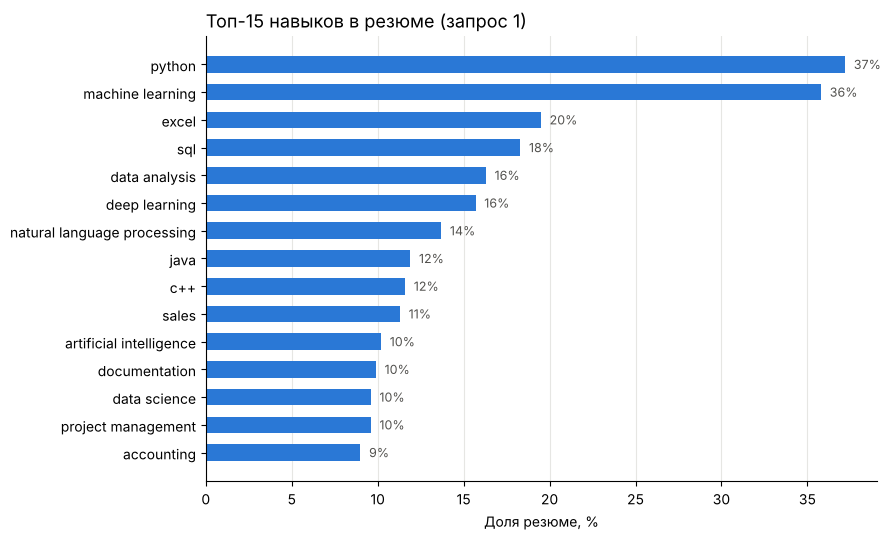

In [14]:
top = df_q1.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["skill"], top["pct_of_resumes"], color=BLUE, height=0.6)
for y, v in enumerate(top["pct_of_resumes"]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
style_ax(ax, "Топ-15 навыков в резюме (запрос 1)", xlabel="Доля резюме, %")
plt.tight_layout(); plt.show()

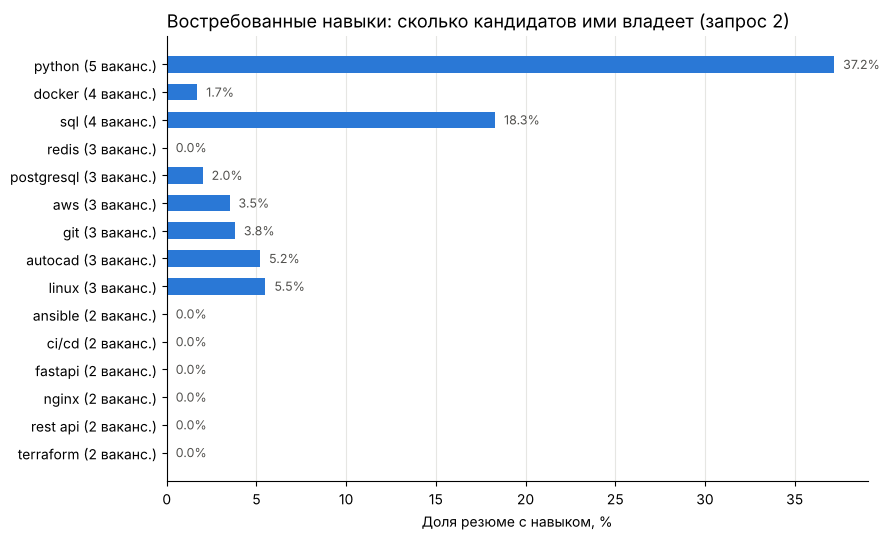

In [15]:
gap = df_q2.head(15).iloc[::-1]
labels = [f"{s} ({n} ваканс.)" for s, n in zip(gap["skill"], gap["jobs_requiring"])]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, gap["pct_resumes"], color=BLUE, height=0.6)
for y, v in enumerate(gap["pct_resumes"]):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
style_ax(ax, "Востребованные навыки: сколько кандидатов ими владеет (запрос 2)",
         xlabel="Доля резюме с навыком, %")
plt.tight_layout(); plt.show()

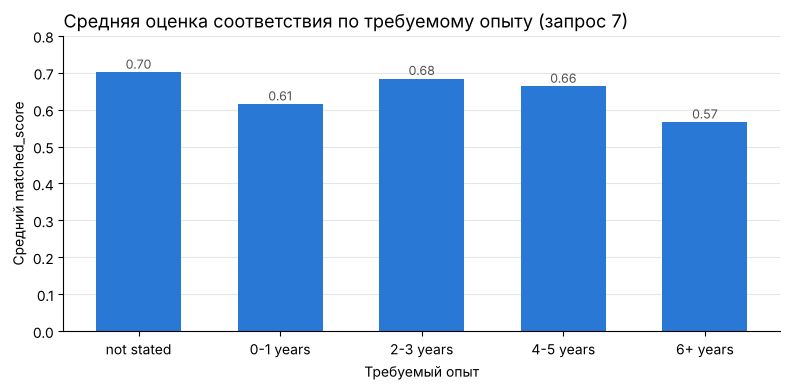

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df_q7["experience_bucket"].str[3:], df_q7["avg_score"], color=BLUE, width=0.6)
for x, v in enumerate(df_q7["avg_score"]):
    ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color="#52514e")
style_ax(ax, "Средняя оценка соответствия по требуемому опыту (запрос 7)",
         xlabel="Требуемый опыт", ylabel="Средний matched_score")
ax.grid(axis="y", color="#e6e6e3"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, 0.8)
plt.tight_layout(); plt.show()

### SQL baseline vs истинная метка

Насколько простой SQL-baseline (точное совпадение навыков, запрос 5) согласуется с `matched_score`?

Корреляция Спирмена overlap_score ~ matched_score: 0.141
Доля пар без единого общего навыка: 93.8%

                    count   mean    std    min    25%   50%    75%    max
has_overlap                                                              
нет общих навыков  7354.0  0.640  0.170  0.000  0.543  0.65  0.783  0.970
≥ 1 общий навык     489.0  0.735  0.116  0.083  0.683  0.75  0.817  0.937


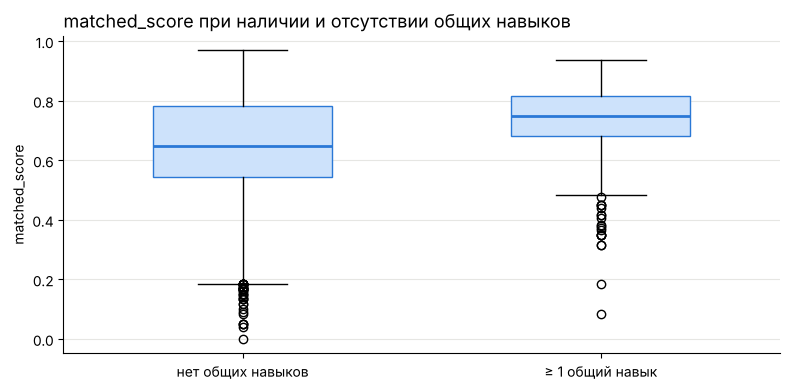

In [17]:
base = df_q5.copy()
base["has_overlap"] = (base["n_matched"] > 0).map({True: "≥ 1 общий навык", False: "нет общих навыков"})
print("Корреляция Спирмена overlap_score ~ matched_score:",
      round(base["overlap_score"].corr(base["matched_score"], method="spearman"), 3))
print("Доля пар без единого общего навыка:", f"{(base['n_matched'] == 0).mean():.1%}\n")
print(base.groupby("has_overlap")["matched_score"].describe().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
groups = ["нет общих навыков", "≥ 1 общий навык"]
ax.boxplot([base.loc[base["has_overlap"] == g, "matched_score"] for g in groups],
           tick_labels=groups, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2))
style_ax(ax, "matched_score при наличии и отсутствии общих навыков", ylabel="matched_score")
ax.grid(axis="y", color="#e6e6e3"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Вывод:** у большинства пар нет ни одного *точно совпадающего* навыка, хотя `matched_score` у многих из них высокий. Точное сравнение строк — слабый baseline: разные формулировки одного навыка («REST API Design» vs «rest api») не совпадают. Это обосновывает переход к TF-IDF и embeddings в основном ноутбуке.

## 5. Один и тот же расчёт в SQL и в Pandas

Считаем топ навыков (запрос 1) средствами Pandas и сравниваем результат и время.

In [18]:
with sqlite3.connect(DEFAULT_DB) as conn:
    rs = pd.read_sql_query("SELECT * FROM resume_skills", conn)
    sk = pd.read_sql_query("SELECT * FROM skills", conn)
    n_resumes = conn.execute("SELECT COUNT(*) FROM resumes").fetchone()[0]

def top_skills_pandas():
    out = (rs.merge(sk, on="skill_id")
             .groupby("name").size().rename("resumes").reset_index()
             .rename(columns={"name": "skill"})
             .sort_values(["resumes", "skill"], ascending=[False, True]).head(20))
    out["pct_of_resumes"] = (100 * out["resumes"] / n_resumes).round(1)
    return out.reset_index(drop=True)

def timeit(fn, repeat=20):
    times = []
    for _ in range(repeat):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return 1000 * sorted(times)[len(times) // 2]   # медиана, мс

sql_ms = timeit(lambda: run_named("top_resume_skills"))
pd_ms = timeit(top_skills_pandas)

a = run_named("top_resume_skills").sort_values(["resumes", "skill"], ascending=[False, True]).reset_index(drop=True)
b = top_skills_pandas()
print("Результаты совпадают:", a[["skill", "resumes"]].equals(b[["skill", "resumes"]]))
pd.DataFrame({"метод": ["SQL (SQLite)", "Pandas (merge + groupby)"],
              "медиана, мс": [round(sql_ms, 2), round(pd_ms, 2)]})

Результаты совпадают: True


,метод,"медиана, мс"
0,SQL (SQLite),2.99
1,Pandas (merge + groupby),10.38


SQL-время включает открытие соединения и чтение результата; Pandas-время — только вычисления на уже загруженных таблицах. На таком объёме обе реализации работают за миллисекунды; преимущество SQL — в том, что данные не нужно целиком загружать в память.

## Итоги

- Данные нормализованы в 10 таблиц (3NF), ER-диаграмма — `docs/er_diagram.png`.
- 10 аналитических запросов (JOIN, LEFT/self-JOIN, GROUP BY/HAVING, CTE, подзапросы, оконные функции ROW_NUMBER / RANK / NTILE / PERCENT_RANK / SUM OVER), все результаты загружаются в Pandas.
- Запрос 4 даёт эталонное ранжирование вакансий для каждого резюме — используется для оценки Precision@k / MRR.
- Запрос 5 показывает, что точное совпадение навыков — слабый baseline, что обосновывает TF-IDF и embeddings.
- Веб-приложение сохраняет каждый анализ в `analysis_results` (запрос 10).